# Giai đoạn D – Học máy: chia tập, tiền xử lý, huấn luyện & tinh chỉnh (B9 – B11)
Phương pháp: [`GIAI_DOAN_D_HOC_MAY/`](../QUY_TRINH_DU_AN/GIAI_DOAN_D_HOC_MAY/README.md)

| Bước | Script | Kết quả đọc trong notebook |
|---|---|---|
| B9 Chia tập | `python -m src.ml.split` | `data/splits/split_summary.json` |
| B10 Tiền xử lý | `src/ml/train.py` (`build_pipeline`) | dùng trực tiếp |
| B11 Huấn luyện | `python -m src.ml.experiments` | `reports/model_comparison.csv`, `tuning_*.csv`, `ablation.csv`, `best_model.json`, MLflow `dropout_ews` |

Notebook **chỉ đọc kết quả đã lưu**; riêng mục 4 chạy lại CV để phân tích ablation theo cặp fold. Tập **Test chưa được dùng** (để dành cho B12).

In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import average_precision_score, precision_recall_curve

from src.ml.experiments import cross_validate, subset_spec
from src.ml.split import load_spec, load_splits

sns.set_theme(style="whitegrid", font_scale=0.95)
FIG_DIR, REP = ROOT / "reports" / "figures", ROOT / "reports"

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=110, bbox_inches="tight")

splits, spec = load_splits(), load_spec()
print(json.dumps(json.loads((ROOT / "data" / "splits" / "split_summary.json").read_text(encoding="utf-8")),
                 ensure_ascii=False, indent=1))

{
 "random_state": 42,
 "rows": {
  "train": 54474,
  "test": 13650,
  "score": 11115
 },
 "students": {
  "train": 14324,
  "test": 3604,
  "score": 11115
 },
 "positives": {
  "train": 5493,
  "test": 1424
 },
 "positive_rate": {
  "train": 0.1008,
  "test": 0.1043
 },
 "n_features": 43,
 "checks_passed": true
}


## 1. B9 – Chia tập
* Chia **theo sinh viên** (`StratifiedGroupKFold`): Train 54.474 dòng / 14.324 SV (10,08% dương), Test 13.650 dòng / 3.604 SV (10,43%); Scoring 11.115 dòng (`Censored = 1`).
* CV 5 fold theo sinh viên trên Train; mọi so sánh và tinh chỉnh dưới đây **chỉ dùng Train**.

## 2. B11 – So sánh mô hình (CV 5 fold, tham số mặc định)

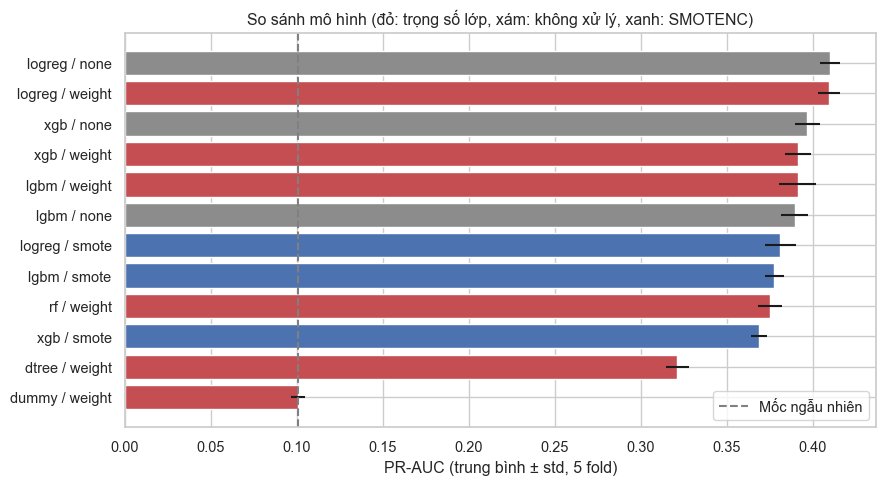

,model,imbalance,pr_auc_mean,pr_auc_std,roc_auc_mean,recall_mean,precision_mean,f1_mean,seconds
6,logreg,none,0.4100,0.0059,0.8030,0.1689,0.6816,0.2707,7.7
1,logreg,weight,0.4095,0.0064,0.8029,0.7024,0.2387,0.3563,8.3
8,xgb,none,0.3968,0.0072,0.7943,0.1840,0.6254,0.2841,14.2
4,xgb,weight,0.3913,0.0077,0.7892,0.6180,0.2681,0.3739,19.2
5,lgbm,weight,0.3912,0.0108,0.7872,0.5913,0.2768,0.3770,13.1
10,lgbm,none,0.3896,0.0078,0.7894,0.1856,0.6227,0.2858,13.0
7,logreg,smote,0.3813,0.0091,0.7839,0.5988,0.2683,0.3705,53.6
11,lgbm,smote,0.3777,0.0057,0.7783,0.2338,0.5395,0.3262,165.0
3,rf,weight,0.3751,0.0068,0.7887,0.5034,0.3251,0.3949,38.2
9,xgb,smote,0.3687,0.0048,0.7740,0.2568,0.5100,0.3416,174.9


In [2]:
cmp_ = pd.read_csv(REP / "model_comparison.csv")
cmp_["cau_hinh"] = cmp_["model"] + " / " + cmp_["imbalance"]
t = cmp_.sort_values("pr_auc_mean")
fig, ax = plt.subplots(figsize=(9, 5))
colors = {"weight": "#C44E52", "none": "#8C8C8C", "smote": "#4C72B0"}
ax.barh(t["cau_hinh"], t["pr_auc_mean"], xerr=t["pr_auc_std"], color=[colors[i] for i in t["imbalance"]])
ax.axvline(t.loc[t["model"] == "dummy", "pr_auc_mean"].iloc[0], color="gray", ls="--", label="Mốc ngẫu nhiên")
ax.set_xlabel("PR-AUC (trung bình ± std, 5 fold)"); ax.legend()
ax.set_title("So sánh mô hình (đỏ: trọng số lớp, xám: không xử lý, xanh: SMOTENC)")
save(fig, "ml_model_comparison.png"); plt.show()
cols = ["model", "imbalance", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "recall_mean", "precision_mean", "f1_mean", "seconds"]
cmp_[cols].sort_values("pr_auc_mean", ascending=False).round(4)

**Nhận xét:**
* Mọi mô hình vượt xa mốc ngẫu nhiên (PR-AUC 0,101). **LogReg dẫn đầu (0,4095 ± 0,0064)**, rồi XGBoost (0,3913) ≈ LightGBM (0,3912) > RF (0,3751) > Decision Tree (0,3212).
* **Trọng số lớp và không xử lý cho cùng PR-AUC** (LogReg 0,4095 so với 0,4100): PR-AUC chỉ phụ thuộc **thứ hạng** xác suất. Trọng số lớp làm xác suất cao lên, nên thay đổi Recall / Precision **tại ngưỡng 0,5** (LogReg: Recall 0,17 → 0,70), không làm mô hình phân biệt tốt hơn. Ngưỡng sẽ được chọn ở B12.
* **SMOTE làm giảm PR-AUC ở cả 3 mô hình** (LogReg 0,410 → 0,381; XGBoost 0,391 → 0,369; LightGBM 0,391 → 0,378) và chậm hơn 7 – 13 lần (xem mục 3).

## 3. Bài học về SMOTE

* **Lần chạy đầu:** SMOTE thường nội suy **mọi** cột, nên sinh ra giá trị không thể có ở cột nhị phân / One-Hot / cột đếm (`Scholarship = 0,43`, `Semester = 2,37`). Mô hình cây tách được dòng tổng hợp chỉ bằng một ngưỡng: XGBoost học trên dữ liệu "50% dương" nhưng dự đoán trung bình chỉ **0,105**, kể cả trên chính tập huấn luyện. SMOTE mất tác dụng mà không báo lỗi.
* **Sửa:** `DiscreteAwareSMOTE` (trong `src/ml/train.py`) tự phát hiện cột rời rạc và dùng **SMOTENC** (lấy giá trị phổ biến của láng giềng thay vì nội suy). Có unit test kiểm tra mẫu tổng hợp giữ số nguyên ở cột rời rạc.
* **Sau khi sửa, SMOTE vẫn kém hơn trọng số lớp**, vì nhiều đặc trưng có **ràng buộc logic** (`Delta_GPA = Sem_GPA − GPA_prev`, kỳ 1 thì không có `GPA_prev`…). Nội suy phá vỡ các ràng buộc này, tạo ra tổ hợp "không thể tồn tại".
* ⇒ **Chọn trọng số lớp** cho mô hình cuối. Bài học: kỹ thuật cân bằng phải phù hợp với **cấu trúc đặc trưng**, không chỉ với tỷ lệ lớp.

## 4. B11 – Tinh chỉnh bằng Optuna

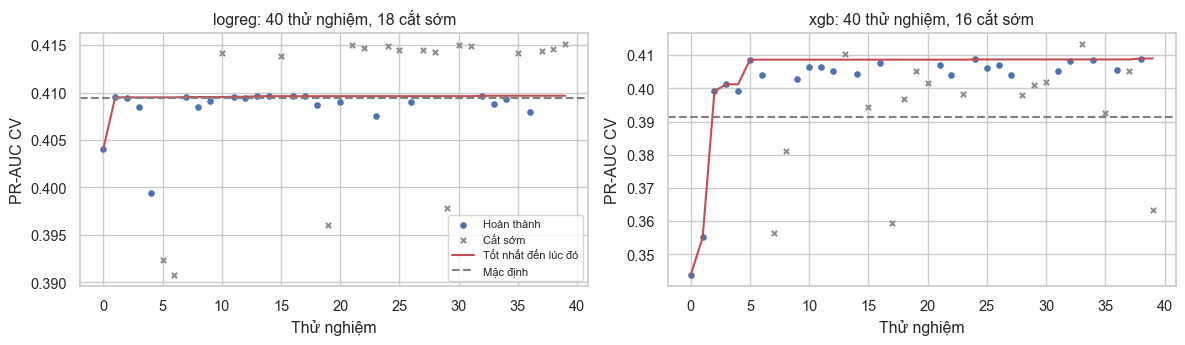

,pr_auc_mean,pr_auc_std,C,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda
logreg,0.409662,0.006478,1.220834,NaN,NaN,NaN,NaN,NaN,NaN,NaN
xgb,0.408993,0.008718,NaN,800.0,0.023225,2.0,2.569253,0.8857,0.796721,0.012827


In [3]:
tuned = json.loads((REP / "tuned_models.json").read_text(encoding="utf-8"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, name in zip(axes, tuned):
    tr = pd.read_csv(REP / f"tuning_{name}.csv")
    done = tr[tr["state"] == "COMPLETE"]
    ax.scatter(tr.index, tr["value"].where(tr["state"] == "COMPLETE"), s=14, label="Hoàn thành", color="#4C72B0")
    ax.scatter(tr.index, tr["value"].where(tr["state"] == "PRUNED"), s=14, marker="x", label="Cắt sớm", color="#8C8C8C")
    ax.plot(tr.index, tr["value"].where(tr["state"] == "COMPLETE").cummax().ffill(), color="#C44E52", label="Tốt nhất đến lúc đó")
    base = cmp_[(cmp_["model"] == name) & (cmp_["imbalance"] == "weight")]["pr_auc_mean"].iloc[0]
    ax.axhline(base, color="gray", ls="--", label="Mặc định")
    ax.set_title(f"{name}: {len(tr)} thử nghiệm, {int((tr['state'] == 'PRUNED').sum())} cắt sớm")
    ax.set_xlabel("Thử nghiệm"); ax.set_ylabel("PR-AUC CV")
axes[0].legend(fontsize=8)
save(fig, "ml_tuning_history.png"); plt.show()
pd.DataFrame({k: {"pr_auc_mean": v["pr_auc_mean"], "pr_auc_std": v["pr_auc_std"], **v["params"]} for k, v in tuned.items()}).T

**Nhận xét:**
* Optuna (TPE + MedianPruner, 40 thử nghiệm mỗi mô hình): XGBoost tăng từ **0,3913 lên 0,4090**; LogReg gần như không đổi (0,4095 → 0,4097, `C = 1,22`, rất gần mặc định).
* Tham số tốt nhất của XGBoost là **`max_depth = 2`** (cây rất nông, nhiều cây, `learning_rate` nhỏ). Cây sâu mặc định (`max_depth = 5`) học quá kỹ. Cây nông nghĩa là mô hình chủ yếu cộng dồn tác động của từng đặc trưng, gần với mô hình tuyến tính.
* Sau tinh chỉnh, **XGBoost ≈ LogReg** (chênh 0,0007, nhỏ hơn nhiều độ lệch chuẩn giữa các fold ~0,0065 – 0,0087).

## 5. B11 – Ablation: đặc trưng chiều dọc có giúp không?

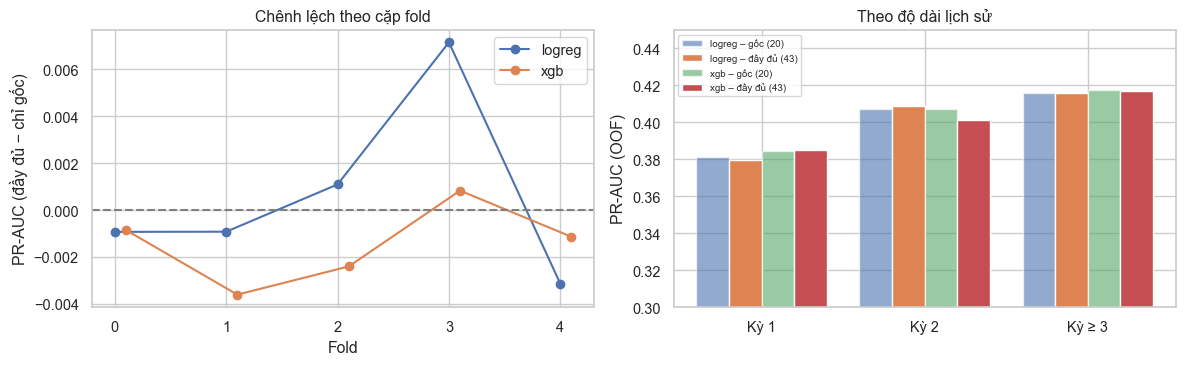

,model,feature_set,n_features,pr_auc_mean,pr_auc_std,roc_auc_mean
0,logreg,baseline,20,0.4090,0.0060,0.8029
1,logreg,full,43,0.4097,0.0065,0.8029
2,xgb,baseline,20,0.4104,0.0072,0.8031
3,xgb,full,43,0.4090,0.0087,0.8022


,mean,std,so_fold_tot_hon
model,,,
logreg,0.0007,0.0039,2
xgb,-0.0014,0.0017,1


,model,nhom,so_dong,goc,day_du
0,logreg,kỳ 1,14324,0.3811,0.3797
1,logreg,kỳ 2,11730,0.4074,0.4089
2,logreg,kỳ ≥ 3,28420,0.4156,0.4157
3,xgb,kỳ 1,14324,0.3846,0.3850
4,xgb,kỳ 2,11730,0.4073,0.4012
5,xgb,kỳ ≥ 3,28420,0.4175,0.4167


In [4]:
abl = pd.read_csv(REP / "ablation.csv")
base_spec = subset_spec(spec, spec["baseline_features"])
sem = splits.X_train["Semester"].values
paired, by_sem = [], []
for name in tuned:
    rb = cross_validate(name, splits.X_train[base_spec["features"]], splits.y_train, splits.groups_train,
                        base_spec, "weight", tuned[name]["params"], feature_set="baseline")
    rf = cross_validate(name, splits.X_train, splits.y_train, splits.groups_train, spec, "weight",
                        tuned[name]["params"], feature_set="full")
    for k, (fb, ff) in enumerate(zip(rb.folds, rf.folds)):
        paired.append({"model": name, "fold": k, "goc": fb["pr_auc"], "day_du": ff["pr_auc"],
                       "chenh_lech": ff["pr_auc"] - fb["pr_auc"]})
    for label, mask in (("kỳ 1", sem == 1), ("kỳ 2", sem == 2), ("kỳ ≥ 3", sem >= 3)):
        y = splits.y_train.values[mask]
        by_sem.append({"model": name, "nhom": label, "so_dong": int(mask.sum()),
                       "goc": average_precision_score(y, rb.oof[mask]),
                       "day_du": average_precision_score(y, rf.oof[mask])})
paired, by_sem = pd.DataFrame(paired), pd.DataFrame(by_sem)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for i, name in enumerate(tuned):
    p = paired[paired["model"] == name]
    axes[0].plot(p["fold"] + i * 0.1, p["chenh_lech"], "o-", label=name)
axes[0].axhline(0, color="gray", ls="--"); axes[0].set_xlabel("Fold")
axes[0].set_ylabel("PR-AUC (đầy đủ − chỉ gốc)"); axes[0].set_title("Chênh lệch theo cặp fold"); axes[0].legend()
x = np.arange(3); w = 0.2
for i, name in enumerate(tuned):
    b = by_sem[by_sem["model"] == name]
    axes[1].bar(x + (2 * i - 1.5) * w, b["goc"], w, label=f"{name} – gốc (20)", alpha=0.6)
    axes[1].bar(x + (2 * i - 0.5) * w, b["day_du"], w, label=f"{name} – đầy đủ (43)")
axes[1].set_xticks(x, ["Kỳ 1", "Kỳ 2", "Kỳ ≥ 3"]); axes[1].set_ylim(0.3, 0.45)
axes[1].set_ylabel("PR-AUC (OOF)"); axes[1].set_title("Theo độ dài lịch sử"); axes[1].legend(fontsize=7)
save(fig, "ml_ablation.png"); plt.show()
display(abl[["model", "feature_set", "n_features", "pr_auc_mean", "pr_auc_std", "roc_auc_mean"]].round(4))
display(paired.groupby("model")["chenh_lech"].agg(["mean", "std", lambda s: int((s > 0).sum())]).rename(columns={"<lambda_0>": "so_fold_tot_hon"}).round(4))
by_sem.round(4)

**Kết quả (trái với giả thuyết ban đầu của đề tài):**
* **Đặc trưng chiều dọc không cải thiện khả năng dự báo.**
  * LogReg: 0,4090 (20 đặc trưng gốc) → 0,4097 (43 đặc trưng), chỉ tốt hơn ở **2/5** fold.
  * XGBoost: 0,4104 → 0,4090, chỉ tốt hơn ở **1/5** fold.
  * Mọi chênh lệch đều nằm trong mức dao động ngẫu nhiên giữa các fold.
* Kể cả với sinh viên có **lịch sử dài** (kỳ ≥ 3, 28.420 dòng), nơi đặc trưng chiều dọc có nhiều thông tin nhất: 0,4156 so với 0,4157 (LogReg).
* **Cách hiểu:** EDA (B6) cho thấy nhóm sắp bỏ học **sa sút dần** qua các kỳ. Nhưng sự sa sút đó **đã thể hiện sẵn trong giá trị hiện tại** (GPA thấp, nợ môn, áp lực tài chính cao). Biết trạng thái hiện tại thì quỹ đạo không thêm thông tin, tức là trong bộ dữ liệu này, rủi ro bỏ học kỳ sau phụ thuộc chủ yếu vào **trạng thái hiện tại**.
* **Kiểm chứng thêm** (3 seed × 5 fold = 15 cặp fold):
  * LogReg: chênh lệch +0,0008, khoảng tin cậy ~95% [−0,0008; +0,0024], chứa 0.
  * XGBoost: −0,0019 [−0,0031; −0,0006].
  * Pipeline có đủ 47 cột (so với 24), nên không có lỗi làm rơi đặc trưng.
  * Chỉ dùng 23 đặc trưng chiều dọc vẫn đạt PR-AUC 0,354, tức là chúng **có thông tin nhưng trùng** với trạng thái hiện tại.
* **Ý nghĩa cho đề tài:**
  * Đây là một **kết quả âm có giá trị**, kiểm chứng bằng thí nghiệm có đối chứng, thay vì mặc định "thêm đặc trưng thì tốt hơn".
  * Đặc trưng chiều dọc vẫn hữu ích cho **mô tả và diễn giải** (EDA, luật kết hợp `GPA_Low + GPA_Drop` ở B8, lý do cảnh báo dễ hiểu cho cố vấn), dù không tăng độ chính xác.

## 6. Mô hình được chọn & dự đoán out-of-fold

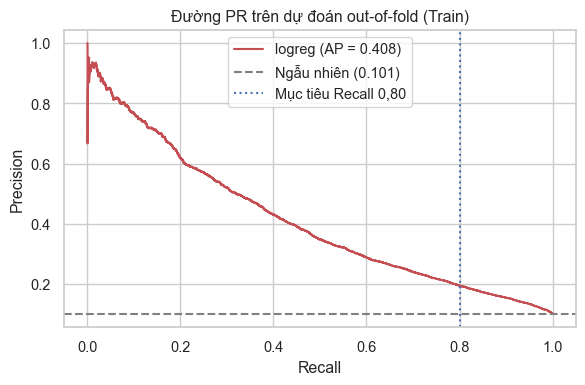

{"model": "logreg", "imbalance": "weight", "feature_set": "full", "params": {"C": 1.2208338797645089}, "runner_up": "xgb"}
Precision tại Recall ≈ 0,80: 0.194


In [5]:
best = json.loads((REP / "best_model.json").read_text(encoding="utf-8"))
oof = pd.read_parquet(ROOT / best["oof_path"])
prec, rec, _ = precision_recall_curve(oof["y"], oof["oof_proba"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rec, prec, color="#C44E52", label=f"{best['model']} (AP = {average_precision_score(oof['y'], oof['oof_proba']):.3f})")
ax.axhline(oof["y"].mean(), color="gray", ls="--", label=f"Ngẫu nhiên ({oof['y'].mean():.3f})")
ax.axvline(0.8, color="#4C72B0", ls=":", label="Mục tiêu Recall 0,80")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Đường PR trên dự đoán out-of-fold (Train)"); ax.legend()
save(fig, "ml_oof_pr_curve.png"); plt.show()
print(json.dumps({k: best[k] for k in ("model", "imbalance", "feature_set", "params", "runner_up")}, ensure_ascii=False))
print(f"Precision tại Recall ≈ 0,80: {prec[np.argmin(np.abs(rec - 0.8))]:.3f}")

**Lựa chọn:** **Logistic Regression** (trọng số lớp, `C = 1,22`, 43 đặc trưng), PR-AUC CV **0,4097 ± 0,0065**, ROC-AUC 0,803. XGBoost tinh chỉnh là lựa chọn dự phòng (0,4090).
* LogReg và XGBoost ngang nhau về độ chính xác; chọn LogReg vì **đơn giản, nhanh, ổn định** (độ lệch chuẩn nhỏ hơn) và **dễ giải thích** (hệ số / SHAP tuyến tính).
* Dự đoán out-of-fold (`data/models/oof_best.parquet`) dùng để **chọn ngưỡng ở B12** mà không chạm vào Test. Tại Recall 0,80, Precision chỉ khoảng 0,2, tức khoảng 4 cảnh báo thì 1 đúng. Đây là đánh đổi cần cân nhắc khi chọn ngưỡng.